# Source 1
data bike counts: https://www.opendata.dk/city-of-copenhagen/cykelparkeringstaellinger


weather api: https://www.dmi.dk/friedata/dokumentation/apis/climate-data-api-1

traffic figures: https://www.opendata.dk/city-of-copenhagen/trafiktal

In [2]:
import pandas as pd

mypath = "cykeltaellinger_2017.csv"
# Load the CSV file into a pandas DataFrame
df = pd.read_csv(mypath)

# Display the first few rows of the DataFrame
df.head()

,FID,id,id_1,taelleomra,pladser,cykelpaapl,cykeludenf,ladcykler,oprettet,redigeret,...,cyk_diff,belaegningspct,label_pladser,label_cykelpaapl,label_cykeludenf,label_ladcykler,label_cykel_sum,label_sum_m_lad,ogc_fid,wkb_geometry
0,cykeltaellinger_2017.fid--52954e74_1a1df5cc488...,ce271ca9-90a8-4906-89f8-e00c3a82e5de,1,taelleomraader_cykelparkering.1,0,0,1,0,05.07.2017 08:52,05.07.2017 08:52,...,1,NaN,NaN,NaN,1.0,NaN,1.0,1.0,1,MULTIPOINT ((724203.6788202389 6176091.17068053))
1,cykeltaellinger_2017.fid--52954e74_1a1df5cc488...,00d5a80d-86db-445a-8477-224156bb2d5e,2,taelleomraader_cykelparkering.1,0,0,1,0,05.07.2017 08:52,05.07.2017 08:52,...,1,NaN,NaN,NaN,1.0,NaN,1.0,1.0,2,MULTIPOINT ((724215.096926301 6176086.780139107))
2,cykeltaellinger_2017.fid--52954e74_1a1df5cc488...,1fe7e8f5-5973-42fc-90c8-b427226e8acd,3,taelleomraader_cykelparkering.1,0,0,1,0,05.07.2017 08:53,05.07.2017 08:53,...,1,NaN,NaN,NaN,1.0,NaN,1.0,1.0,3,MULTIPOINT ((724224.5544342333 6176082.5794792...
3,cykeltaellinger_2017.fid--52954e74_1a1df5cc488...,09dee499-0f6a-4689-b656-68b73dc85092,4,taelleomraader_cykelparkering.1,0,0,1,0,05.07.2017 08:53,05.07.2017 08:53,...,1,NaN,NaN,NaN,1.0,NaN,1.0,1.0,4,MULTIPOINT ((724230.2287144866 6176084.0803268...
4,cykeltaellinger_2017.fid--52954e74_1a1df5cc488...,6fa55861-d68b-4edd-a5a5-f528043b7c1d,5,taelleomraader_cykelparkering.1,0,0,1,0,05.07.2017 08:54,05.07.2017 08:54,...,1,NaN,NaN,NaN,1.0,NaN,1.0,1.0,5,MULTIPOINT ((724273.5746011261 6176101.5674572...


In [3]:
trimmed_counts = df[['cykel_sum', 'latitude', 'longitude', "wkb_geometry"]]
trimmed_counts.head()

,cykel_sum,latitude,longitude,wkb_geometry
0,1,55.678744,12.566182,MULTIPOINT ((724203.6788202389 6176091.17068053))
1,1,55.678699,12.566359,MULTIPOINT ((724215.096926301 6176086.780139107))
2,1,55.678657,12.566506,MULTIPOINT ((724224.5544342333 6176082.5794792...
3,1,55.678668,12.566597,MULTIPOINT ((724230.2287144866 6176084.0803268...
4,1,55.678805,12.567300,MULTIPOINT ((724273.5746011261 6176101.5674572...


In [4]:
# Sort the data to find where the most bikes are located
top_bike_locations = trimmed_counts.sort_values(by='cykel_sum', ascending=False)

# Display the top 10 locations with the most bikes
print("Top 10 locations with the most bikes parked:")
display(top_bike_locations.head(10))

Top 10 locations with the most bikes parked:


,cykel_sum,latitude,longitude,wkb_geometry
2303,83,55.678986,12.584996,MULTIPOINT ((725384.5912545983 6176179.0916048...
2305,79,55.678991,12.585054,MULTIPOINT ((725388.2037974664 6176179.8975415...
3304,71,55.697975,12.597889,MULTIPOINT ((726085.0350183152 6178332.8950534...
31685,65,55.658953,12.589363,MULTIPOINT ((725774.376205998 6173965.480948751))
46640,61,55.683172,12.572102,MULTIPOINT ((724550.3322797657 6176602.8763409...
2383,61,55.678660,12.584298,MULTIPOINT ((725342.5767984227 6176140.6218221))
16945,58,55.663953,12.515192,MULTIPOINT ((721082.9042383047 6174282.5187956...
39992,58,55.683167,12.554759,MULTIPOINT ((723460.6118393334 6176546.2407550...
35771,56,55.681850,12.563073,MULTIPOINT ((723990.5646061578 6176426.6244095...
28234,56,55.706247,12.538862,MULTIPOINT ((722330.6277903533 6179061.8665546...


### Average Hour for the 55 days we have

In [5]:
# Convert 'oprettet' (created) or other potential date columns to datetime
# to analyze temporal patterns if available
if 'oprettet' in df.columns:
    df['oprettet_dt'] = pd.to_datetime(df['oprettet'], format='%d.%m.%Y %H:%M', errors='coerce')
    df['hour'] = df['oprettet_dt'].dt.hour
    df['weekday'] = df['oprettet_dt'].dt.day_name()
    df['month'] = df['oprettet_dt'].dt.month
    
    # Group by hour to see peak times
    hourly_counts = df.groupby('hour')['cykel_sum'].sum().reset_index()
    print("Hourly bike count totals:")
    display(hourly_counts)
else:
    print("No 'oprettet' column found for temporal analysis. Please review the info output above.")

Hourly bike count totals:


,hour,cykel_sum
0,7,37
1,8,4462
2,9,21604
3,10,34684
4,11,30464
5,12,21951
6,13,21839
7,14,27097
8,15,21204
9,16,16497


In [6]:
df['date_only'] = df['oprettet_dt'].dt.date

# Group by date and hour to examine patterns
date_hour_counts = df.groupby(['date_only', 'hour'])['cykel_sum'].sum().reset_index()

# Pivot the table to easily compare hours across different dates
date_hour_pivot = date_hour_counts.pivot(index='hour', columns='date_only', values='cykel_sum').fillna(0)
print("Bike counts per hour across different collection dates:")
display(date_hour_pivot)

Bike counts per hour across different collection dates:


date_only,2017-07-05,2017-07-06,2017-07-10,2017-07-11,2017-07-12,2017-07-13,2017-07-14,2017-07-17,2017-07-18,2017-07-19,...,2017-09-19,2017-09-20,2017-09-21,2017-09-22,2017-09-25,2017-09-26,2017-09-27,2017-09-28,2017-09-29,2017-10-10
hour,,,,,,,,,,,,,,,,,,,,,
7,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8,44.0,0.0,0.0,0.0,0.0,0.0,0.0,58.0,0.0,0.0,...,0.0,349.0,545.0,0.0,113.0,496.0,0.0,0.0,0.0,0.0
9,204.0,0.0,0.0,638.0,0.0,0.0,0.0,338.0,139.0,0.0,...,756.0,594.0,1404.0,511.0,1245.0,370.0,4.0,193.0,0.0,0.0
10,0.0,0.0,0.0,347.0,0.0,0.0,0.0,347.0,161.0,0.0,...,1922.0,458.0,1816.0,1358.0,2181.0,923.0,1441.0,0.0,0.0,0.0
11,0.0,0.0,0.0,693.0,0.0,0.0,0.0,0.0,0.0,0.0,...,959.0,373.0,933.0,1685.0,1536.0,886.0,1060.0,0.0,932.0,0.0
12,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,346.0,432.0,703.0,1667.0,815.0,762.0,340.0,0.0,885.0,0.0
13,572.0,264.0,376.0,0.0,201.0,757.0,50.0,65.0,0.0,81.0,...,371.0,565.0,521.0,1188.0,548.0,302.0,465.0,0.0,0.0,204.0
14,1003.0,163.0,72.0,0.0,218.0,813.0,391.0,834.0,325.0,1123.0,...,330.0,342.0,657.0,632.0,840.0,833.0,887.0,0.0,0.0,474.0
15,154.0,145.0,0.0,0.0,0.0,116.0,12.0,42.0,0.0,120.0,...,731.0,563.0,690.0,505.0,973.0,1203.0,560.0,0.0,0.0,548.0


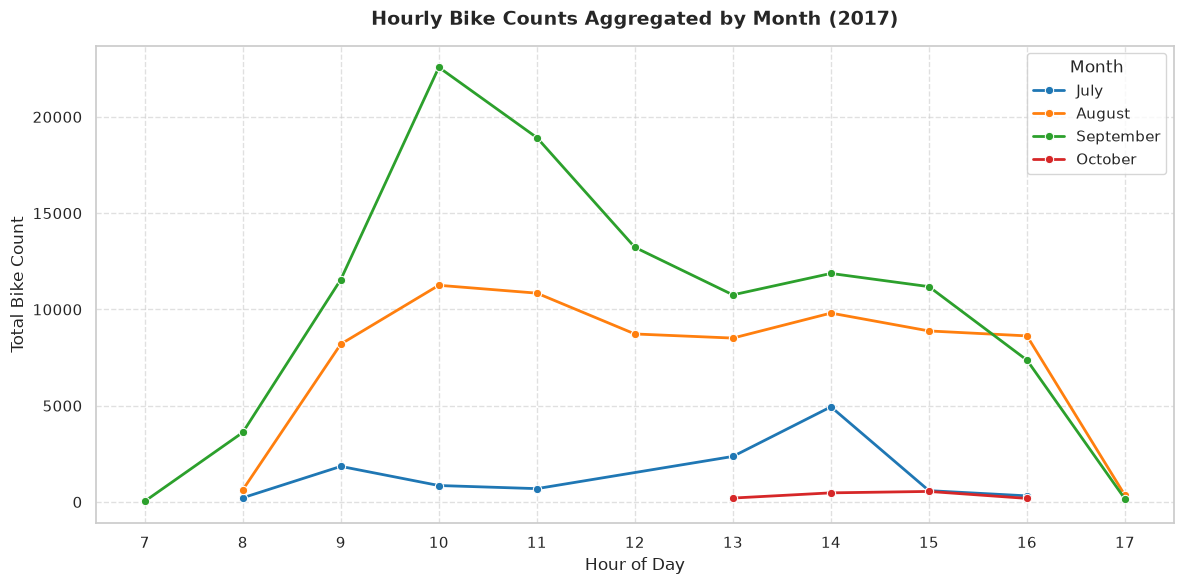

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
# Extract month name for a cleaner plot legend
df['month_name'] = df['oprettet_dt'].dt.strftime('%B')

# Group bike counts by month and hour
month_hour_counts = df.groupby(['month_name', 'hour'])['cykel_sum'].sum().reset_index()
day_hour_counts = df.groupby(['date_only', 'hour'])['cykel_sum'].sum().reset_index()

# Define month order for consistent plotting
month_order = ['July', 'August', 'September', 'October']
month_hour_counts['month_name'] = pd.Categorical(month_hour_counts['month_name'], categories=month_order, ordered=True)
month_hour_counts = month_hour_counts.sort_values(['month_name', 'hour'])

# Plot the aggregated monthly hourly trends
plt.figure(figsize=(12, 6))
sns.set_theme(style="whitegrid")
sns.lineplot(data=month_hour_counts, x='hour', y='cykel_sum', hue='month_name', marker='o', linewidth=2, palette='tab10')

plt.title('Hourly Bike Counts Aggregated by Month (2017)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Hour of Day', fontsize=12)
plt.ylabel('Total Bike Count', fontsize=12)
plt.xticks(range(7, 18))  # Set ticks based on the hours present in the dataset
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(title='Month', loc='upper right', frameon=True)
plt.tight_layout()
plt.show()

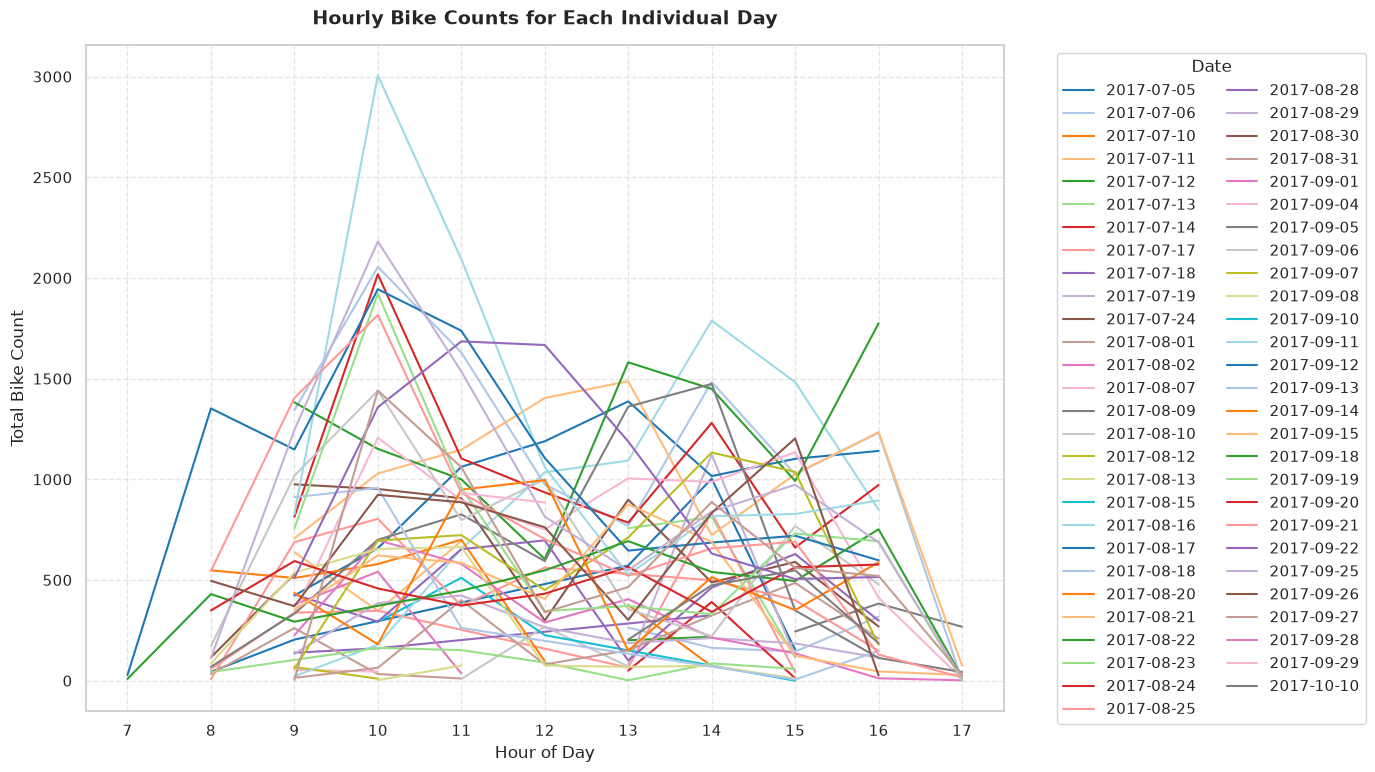

In [8]:
plt.figure(figsize=(14, 8))
sns.set_theme(style="whitegrid")
sns.lineplot(data=date_hour_counts, x='hour', y='cykel_sum', hue='date_only', legend='full', palette='tab20', linewidth=1.5)

plt.title('Hourly Bike Counts for Each Individual Day', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Hour of Day', fontsize=12)
plt.ylabel('Total Bike Count', fontsize=12)
plt.xticks(range(7, 18))
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title='Date', bbox_to_anchor=(1.05, 1), loc='upper left', ncol=2)
plt.tight_layout()
plt.show()

## Get the location groups with the most bikes per month

In [9]:
# Round coordinates to 2 decimal places to define generalized 'neighborhood' areas
df['lat_round'] = df['latitude'].round(2)
df['lon_round'] = df['longitude'].round(2)

# Identify the top 5 general areas with the highest cumulative bike counts
top_areas = df.groupby(['lat_round', 'lon_round'])['cykel_sum'].sum().reset_index()
top_5_areas = top_areas.sort_values(by='cykel_sum', ascending=False).head(5)

# Create a friendly neighborhood label for these top 5 areas
top_5_areas['area_label'] = top_5_areas.apply(
    lambda r: f"Area ({r['lat_round']:.2f}, {r['lon_round']:.2f})", axis=1
)

print("Top 5 General Areas identified:")
display(top_5_areas)

# Filter the main dataframe to focus on observations within these 5 areas
area_keys = list(zip(top_5_areas['lat_round'], top_5_areas['lon_round']))
df_top_areas = df[df.set_index(['lat_round', 'lon_round']).index.isin(area_keys)].copy()

# Map the area labels back to our filtered dataset
area_label_map = dict(zip(zip(top_5_areas['lat_round'], top_5_areas['lon_round']), top_5_areas['area_label']))
df_top_areas['area_name'] = df_top_areas.apply(lambda r: area_label_map[(r['lat_round'], r['lon_round'])], axis=1)

Top 5 General Areas identified:


,lat_round,lon_round,cykel_sum,area_label
102,55.70,12.55,6847,"Area (55.70, 12.55)"
72,55.68,12.57,6737,"Area (55.68, 12.57)"
59,55.67,12.56,6187,"Area (55.67, 12.56)"
106,55.70,12.59,5902,"Area (55.70, 12.59)"
58,55.67,12.55,5783,"Area (55.67, 12.55)"


In [12]:
# Print the record count and total bike counts for each month
monthly_summary = df.groupby('month_name', observed=False).agg(
    records_count=('cykel_sum', 'count'),
    total_bikes=('cykel_sum', 'sum')
).reset_index()
print("Data distribution across months:")
display(monthly_summary)

Data distribution across months:


,month_name,records_count,total_bikes
0,August,18366,75835
1,July,2547,11830
2,October,396,1412
3,September,25737,111263


Active months to include in the plot: ['August', 'July', 'October', 'September']


<Figure size 1600x500 with 0 Axes>

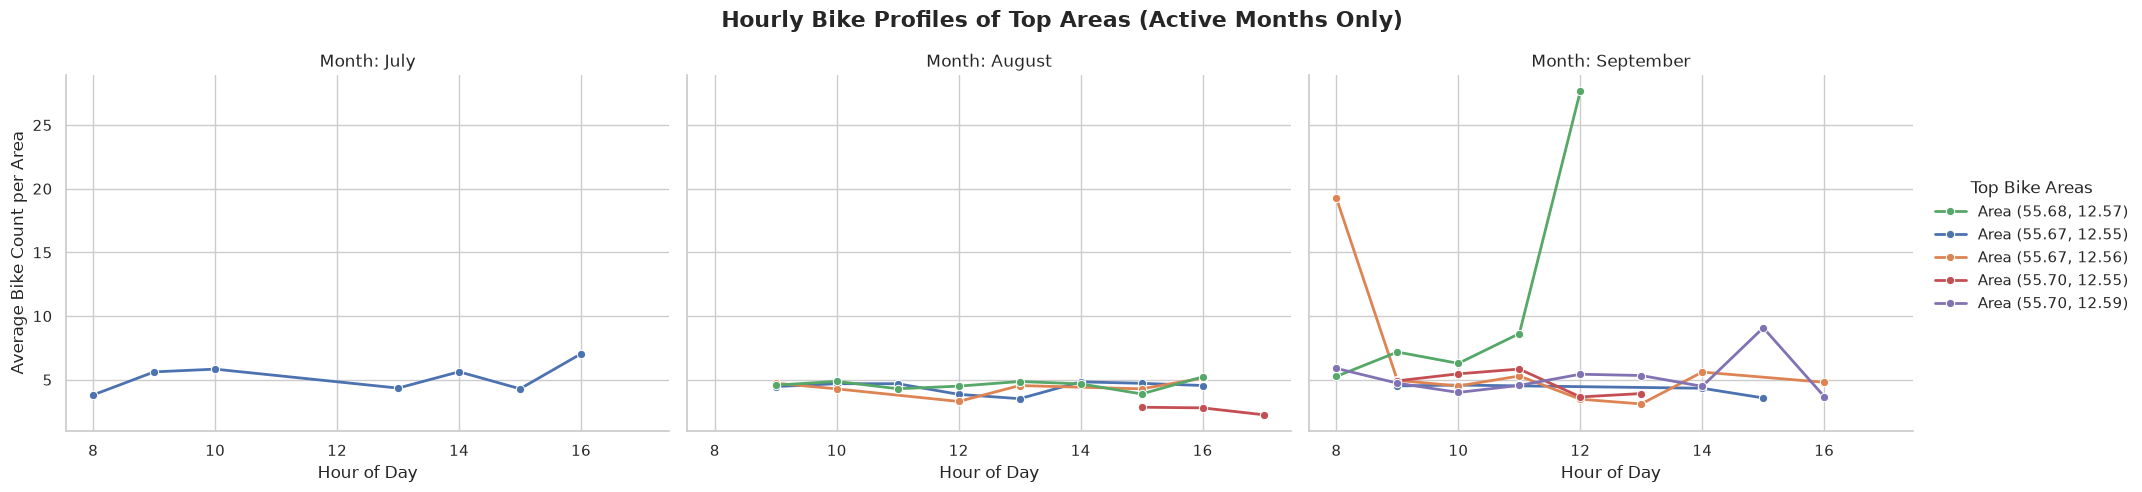

In [13]:
# Filter out months that have fewer than 100 records to keep the analysis clean and representative
active_months = monthly_summary[monthly_summary['records_count'] > 100]['month_name'].tolist()
print(f"Active months to include in the plot: {active_months}")
# Group the filtered area data by Area, Month, and Hour to compare hourly profiles
area_hourly_monthly = df_top_areas.groupby(['area_name', 'month_name', 'hour'])['cykel_sum'].mean().reset_index()
area_hourly_monthly = area_hourly_monthly.dropna(subset=['cykel_sum'])

# Re-filter the hourly trend data to include only active months
filtered_area_hourly = area_hourly_monthly[area_hourly_monthly['month_name'].isin(active_months)]

# Plot the hourly trends for each top general area across active months only
plt.figure(figsize=(16, 5))
sns.set_theme(style="whitegrid")

g = sns.FacetGrid(
    filtered_area_hourly, 
    col="month_name", 
    col_wrap=3, 
    height=5, 
    aspect=1.3, 
    col_order=[m for m in ['July', 'August', 'September'] if m in active_months]
)

g.map_dataframe(
    sns.lineplot, 
    x="hour", 
    y="cykel_sum", 
    hue="area_name", 
    marker="o", 
    linewidth=2
)

g.add_legend(title="Top Bike Areas")
g.set_titles("Month: {col_name}")
g.set_axis_labels("Hour of Day", "Average Bike Count per Area")

plt.subplots_adjust(top=0.85)
g.fig.suptitle('Hourly Bike Profiles of Top Areas (Active Months Only)', fontsize=16, fontweight='bold')
plt.show()

Target mean: 164.7   median: 100.0
Model    MAE: 54.33   R2: 0.732
Baseline MAE: 157.11   R2: -0.302


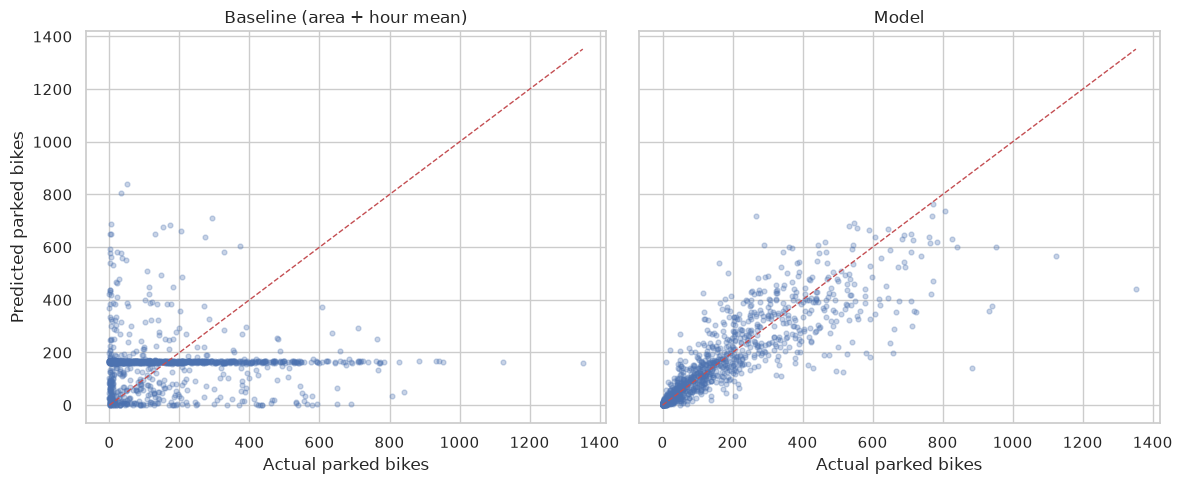

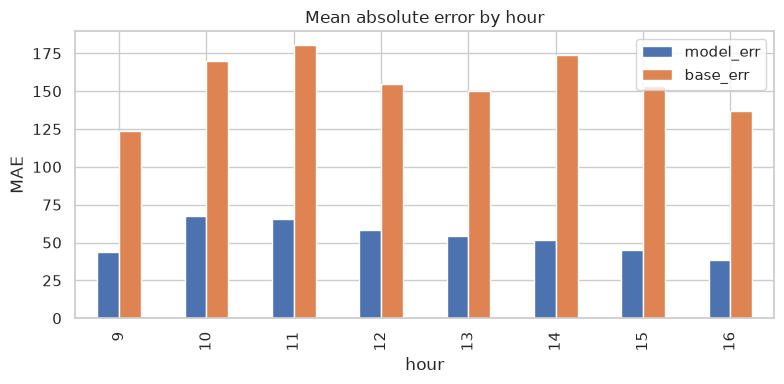

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import mean_absolute_error, r2_score

# --- Data ---
df['weekday_num'] = df['oprettet_dt'].dt.weekday

agg = (df[df['hour'].between(9, 16)]
         .groupby(['taelleomra', 'date_only', 'hour'])
         .agg(bikes=('cykel_sum', 'sum'),
              n_records=('cykel_sum', 'count'),
              lat=('latitude', 'mean'),
              lon=('longitude', 'mean'),
              weekday=('weekday_num', 'first'),
              month=('month', 'first'))
         .reset_index())

agg['area'] = agg['taelleomra'].astype('category')
features = ['area', 'lat', 'lon', 'hour', 'weekday', 'month', 'n_records']
X, y, groups = agg[features], agg['bikes'], agg['date_only']

model = HistGradientBoostingRegressor(loss='poisson', categorical_features='from_dtype',
                                      max_iter=300, learning_rate=0.05)

# --- Evaluation ---
cv = GroupKFold(n_splits=5)
pred = cross_val_predict(model, X, y, cv=cv, groups=groups)

base_pred = np.full(len(y), np.nan)
for tr, te in cv.split(X, y, groups):
    tbl = agg.iloc[tr].groupby(['taelleomra', 'hour'])['bikes'].mean()
    key = agg.iloc[te].set_index(['taelleomra', 'hour']).index
    base_pred[te] = tbl.reindex(key).fillna(y.iloc[tr].mean()).values

print(f"Target mean: {y.mean():.1f}   median: {y.median():.1f}")
print(f"Model    MAE: {mean_absolute_error(y, pred):.2f}   R2: {r2_score(y, pred):.3f}")
print(f"Baseline MAE: {mean_absolute_error(y, base_pred):.2f}   R2: {r2_score(y, base_pred):.3f}")

# --- Plots ---
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
lim = max(y.max(), pred.max(), base_pred.max())
for ax, p, title in zip(axes, [base_pred, pred], ['Baseline (area + hour mean)', 'Model']):
    ax.scatter(y, p, alpha=0.3, s=12)
    ax.plot([0, lim], [0, lim], 'r--', lw=1)
    ax.set_title(title)
    ax.set_xlabel('Actual parked bikes')
axes[0].set_ylabel('Predicted parked bikes')
plt.tight_layout()
plt.show()

err = (agg.assign(model_err=np.abs(y - pred), base_err=np.abs(y - base_pred))
          .groupby('hour')[['model_err', 'base_err']].mean())
err.plot(kind='bar', figsize=(8, 4), title='Mean absolute error by hour')
plt.ylabel('MAE')
plt.tight_layout()
plt.show()

In [29]:
first_hour = 9
last_hour = 13

min_hours = last_hour - (first_hour + 1)
# Total bikes per location and hour, pooled over all collection days
loc_hour = (df[df['hour'].between(first_hour, last_hour)]
              .groupby(['taelleomra', 'hour'])['cykel_sum']
              .sum(min_count=1)          # stays NaN if every value is null
              .unstack()
              .reindex(columns=range(first_hour, last_hour + 1)))

# For each location, how many hours have data that is not null and not zero
nonzero_hours = (loc_hour.notna() & (loc_hour > 0)).sum(axis=1)

good_locs = nonzero_hours[nonzero_hours >= min_hours].index
print(len(good_locs), "of", len(nonzero_hours), "locations have >=", min_hours, "non-zero hours")

# The filtered data
df_good = df[df['taelleomra'].isin(good_locs) & df['hour'].between(first_hour, last_hour)]

# To see how many locations pass at each threshold
print(nonzero_hours.value_counts().sort_index())

101 of 232 locations have >= 3 non-zero hours
1    74
2    57
3    34
4    30
5    37
Name: count, dtype: int64
